# Phase 1 - Convolutional Neural Networks

**Students:** Samarth Kale, Saarth Kishore

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

Section 5 asks you to run different hyperparameters- please make sure to run all your codes and make sure outputs are neat enough to read.

You may find [this](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) Pytorch tutorial helpful.


## **Overview**
1. Loading & Visualizing Data
2. Utility Functions
3. Define CNNs
4. Train and Evaluate
5. Experiments and Reporting

In [2]:
# Run to import necessary libraries
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

# **1. Loading & Visualizing Data**

Please use MNIST for this phase. MNIST is a digit classification dataset, with greyscale 28x28 images, and 10 classes (numbers 0-9).

See [documentation.](https://pytorch.org/vision/0.15/generated/torchvision.datasets.MNIST.html) You can also see the `MNIST_Tutorial.ipynb`.

Please complete loading the data below.

Please also complete `show_imgs()`. Function should input the dataloader, and show 10 random images and their labels.

In [3]:
# MNIST mean/std normalization helps optimization
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_data = datasets.MNIST(root='./data', train=True, download=True, transform=mnist_transform)

test_data = datasets.MNIST(root='./data', train=False, download=True, transform=mnist_transform)

batch_size = 32

# num_workers=0 is the safe choice for Jupyter on Windows
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)

test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda:0


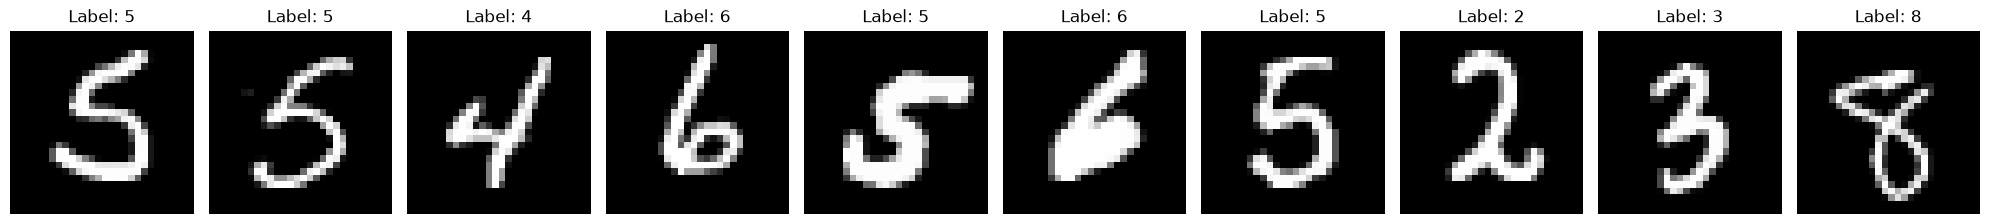

In [4]:
# Function should input the dataloader, and show random 10 images and their labels as title to plot
def show_imgs(dataloader, n=10):
    dataset = dataloader.dataset
    idxs = np.random.choice(len(dataset), n, replace=False)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))
    for ax, idx in zip(axes, idxs):
        img, label = dataset[idx]
        img = img * 0.3081 + 0.1307          # undo normalization for display
        ax.imshow(img.squeeze().numpy(), cmap='gray')
        ax.set_title(f'Label: {label}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_imgs(train_loader)

## **2. Utility Functions**

Please complete `train()` and `plot_learning_curves()` functions. `test_accuracy()` has already been provided to you.

In [5]:
# Provided function, with small fixes: it used the global `net` and `.cuda()`,
# and the cells below call it without a `device` argument.
def test_accuracy(model, test_loader, input_size, device=device):
    model.to(device)
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for test_data in test_loader:
            images, labels = test_data[0].to(device), test_data[1].to(device)
            images = images.view(-1, input_size)   # CNNs reshape back to (N,1,28,28) in forward()
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    print('Accuracy: %.2f %%' % (100 * correct / total))
    return 100 * correct / total

## **2.1 Train Function**
Please refer to the train function in `MNIST_Classifier.ipynb` to complete this function.
- You will need to store the loss and accuracies per iteration (to plot later). Do this for both the train set and test set!
- Please print the loss, accuracy and time taken **each epoch** for both train and test sets

In [6]:
import time

def train(model, loss_fn, optimizer, train_loader, test_loader, batch_size, num_epochs, device):
    """Trains the model and records loss/accuracy per iteration for train and test.

    Train metrics: the current training batch.
    Test metrics: one test batch per iteration (cycling through the test set), so the
    test curve has the same x-axis as the train curve without a full eval every step.
    A full test pass is also printed at the end of each epoch.
    """
    model.to(device)
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    test_iter = iter(test_loader)

    for epoch in range(num_epochs):
        start = time.time()
        model.train()
        epoch_loss, epoch_correct, epoch_total = 0.0, 0, 0

        for images, labels in train_loader:
            images = images.view(images.size(0), -1).to(device)   # flatten; CNNs reshape internally
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            preds = outputs.argmax(1)
            correct = (preds == labels).sum().item()
            history['train_loss'].append(loss.item())
            history['train_acc'].append(100 * correct / labels.size(0))
            epoch_loss += loss.item() * labels.size(0)
            epoch_correct += correct
            epoch_total += labels.size(0)

            # one test batch per iteration
            try:
                t_images, t_labels = next(test_iter)
            except StopIteration:
                test_iter = iter(test_loader)
                t_images, t_labels = next(test_iter)
            model.eval()
            with torch.no_grad():
                t_images = t_images.view(t_images.size(0), -1).to(device)
                t_labels = t_labels.to(device)
                t_out = model(t_images)
                history['test_loss'].append(loss_fn(t_out, t_labels).item())
                history['test_acc'].append(100 * (t_out.argmax(1) == t_labels).float().mean().item())
            model.train()

        # full test pass for the epoch summary
        model.eval()
        t_loss, t_correct, t_total = 0.0, 0, 0
        with torch.no_grad():
            for t_images, t_labels in test_loader:
                t_images = t_images.view(t_images.size(0), -1).to(device)
                t_labels = t_labels.to(device)
                t_out = model(t_images)
                t_loss += loss_fn(t_out, t_labels).item() * t_labels.size(0)
                t_correct += (t_out.argmax(1) == t_labels).sum().item()
                t_total += t_labels.size(0)

        print(f'Epoch [{epoch + 1}/{num_epochs}] '
              f'Train Loss: {epoch_loss / epoch_total:.4f}  Train Acc: {100 * epoch_correct / epoch_total:.2f}%  |  '
              f'Test Loss: {t_loss / t_total:.4f}  Test Acc: {100 * t_correct / t_total:.2f}%  |  '
              f'Time: {time.time() - start:.1f}s')

    return history

## **2.2 Plot Learning Curves Function**
Plot the loss and accuracies from training. Example outputs will be provided in lab walkthrough.

In [7]:
def plot_learning_curve(history, title='', smooth=50):
    """Plots per-iteration loss and accuracy for train and test (moving average for readability)."""
    def ma(x, k):
        x = np.asarray(x, dtype=float)
        if len(x) < k:
            return x
        return np.convolve(x, np.ones(k) / k, mode='valid')

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(ma(history['train_loss'], smooth), label='Train')
    axes[0].plot(ma(history['test_loss'], smooth), label='Test')
    axes[0].set_title(f'Loss {title}')
    axes[0].set_xlabel('Iteration')
    axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(ma(history['train_acc'], smooth), label='Train')
    axes[1].plot(ma(history['test_acc'], smooth), label='Test')
    axes[1].set_title(f'Accuracy {title}')
    axes[1].set_xlabel('Iteration')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

# **3. Define CNNs**

A 1-Layer Architecture is already defined for you (`Net`) as a reference. Please complete the definitions of the 2-Layer CNN (`Net2`). The network architecture definitions are provided to you. You must calculate some dimensions yourself.

**NOTE:** For now, please use ReLU activation. You will experiment with other activations in Section 5.

In [8]:
class Net(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net,self).__init__()
        self.fc1 = nn.Linear(input_size, 500)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(500, num_classes)

    def forward(self,x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

## **3.1 Create a 2-Layer CNN**
Complete `Net2` class.

 Network Architecture:
* ***Layer 1 (Input)***: Convolutional; input channel = 1, output channel = 20, kernel size = 3, step size = 1.
* ***Layer 2 (Output)***: Fully connected; input dimension = < you find out >, output dimension = < you find out >.

In [9]:
# Define 2-Layer Network
# Conv: 1 -> 20 channels, k=3, stride=1, no padding: 28x28 -> 26x26
# FC input = 20 * 26 * 26 = 13520, FC output = 10 classes
class Net2(nn.Module):
    def __init__(self, num_classes=10, activation=nn.ReLU):
        super(Net2, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=20, kernel_size=3, stride=1)
        self.act = activation()
        self.fc1 = nn.Linear(20 * 26 * 26, num_classes)

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)      # accept flattened input like Net
        out = self.act(self.conv1(x))
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        return out

# **4. Train and Evaluate**

## **4.1 Training and Evaluating 1-Layer CNN**

Here, you must test your utility functions (`train()` and `plot_learning_curves()`)with the 1-Layer Model. Please at this stage ensure your utility functions are working correctly. The TAs will provide sample outputs in lab walkthrough.

**NOTE**: You can repeatedly use this below code block in Section 5 to run experiments, while making changes to the hyperparameters as required.

Epoch [1/10] Train Loss: 0.3565  Train Acc: 90.57%  |  Test Loss: 0.2745  Test Acc: 92.99%  |  Time: 26.8s
Epoch [2/10] Train Loss: 0.2739  Train Acc: 93.08%  |  Test Loss: 0.2580  Test Acc: 93.30%  |  Time: 43.2s
Epoch [3/10] Train Loss: 0.2558  Train Acc: 93.71%  |  Test Loss: 0.2860  Test Acc: 93.95%  |  Time: 32.9s
Epoch [4/10] Train Loss: 0.2526  Train Acc: 93.92%  |  Test Loss: 0.2724  Test Acc: 94.18%  |  Time: 30.8s
Epoch [5/10] Train Loss: 0.2353  Train Acc: 94.36%  |  Test Loss: 0.3036  Test Acc: 94.01%  |  Time: 26.0s
Epoch [6/10] Train Loss: 0.2340  Train Acc: 94.26%  |  Test Loss: 0.3034  Test Acc: 94.10%  |  Time: 25.9s
Epoch [7/10] Train Loss: 0.2303  Train Acc: 94.63%  |  Test Loss: 0.4379  Test Acc: 93.31%  |  Time: 25.7s
Epoch [8/10] Train Loss: 0.2188  Train Acc: 94.91%  |  Test Loss: 0.2956  Test Acc: 94.64%  |  Time: 28.4s
Epoch [9/10] Train Loss: 0.2196  Train Acc: 94.84%  |  Test Loss: 0.3544  Test Acc: 92.48%  |  Time: 26.0s
Epoch [10/10] Train Loss: 0.2080  Tra

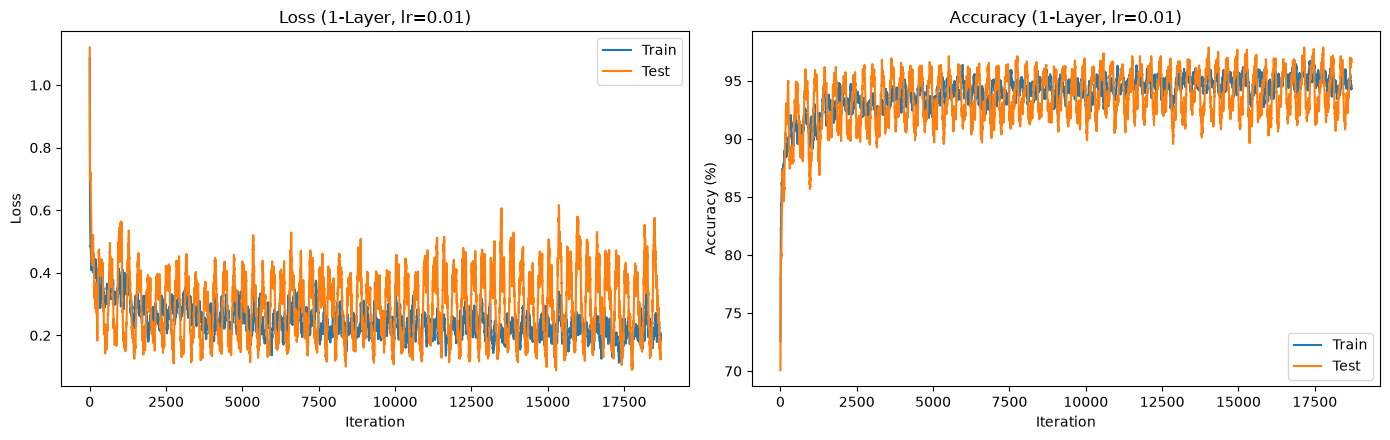

Accuracy: 94.44 %


94.44

In [10]:
# Define Parameters
input_size = 28 * 28
num_classes = 10
lr = 0.01
num_epochs = 10

# Instantiate 1-Layer Model
net = Net(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model
history = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(history, title='(1-Layer, lr=0.01)')

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

## **4.2 Training and Evaluating 2-Layer CNN**


Please also train your 2-Layer network to ensure it is working properly.

Epoch [1/10] Train Loss: 0.1949  Train Acc: 95.06%  |  Test Loss: 0.0973  Test Acc: 96.96%  |  Time: 25.7s
Epoch [2/10] Train Loss: 0.0901  Train Acc: 97.31%  |  Test Loss: 0.0942  Test Acc: 97.41%  |  Time: 25.5s
Epoch [3/10] Train Loss: 0.0781  Train Acc: 97.92%  |  Test Loss: 0.1272  Test Acc: 97.09%  |  Time: 25.4s
Epoch [4/10] Train Loss: 0.0530  Train Acc: 98.48%  |  Test Loss: 0.1524  Test Acc: 97.10%  |  Time: 146.4s
Epoch [5/10] Train Loss: 0.0584  Train Acc: 98.50%  |  Test Loss: 0.1871  Test Acc: 97.07%  |  Time: 24.9s
Epoch [6/10] Train Loss: 0.0512  Train Acc: 98.82%  |  Test Loss: 0.2855  Test Acc: 96.72%  |  Time: 24.8s
Epoch [7/10] Train Loss: 0.0459  Train Acc: 98.99%  |  Test Loss: 0.2906  Test Acc: 97.12%  |  Time: 25.3s
Epoch [8/10] Train Loss: 0.0446  Train Acc: 99.14%  |  Test Loss: 0.3306  Test Acc: 96.78%  |  Time: 26.2s
Epoch [9/10] Train Loss: 0.0452  Train Acc: 99.19%  |  Test Loss: 0.3489  Test Acc: 97.01%  |  Time: 26.9s
Epoch [10/10] Train Loss: 0.0454  Tr

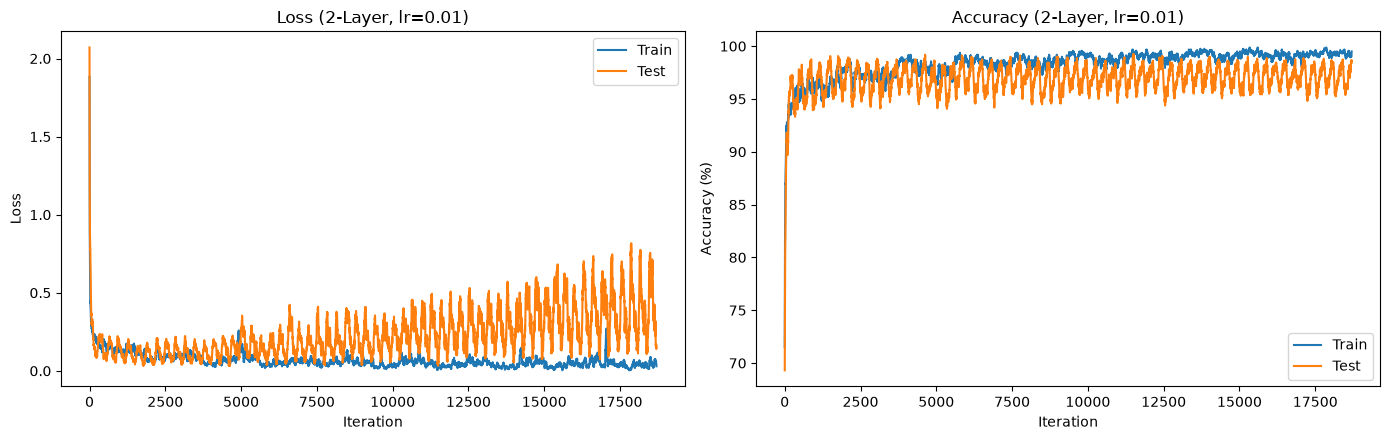

Accuracy: 96.95 %


In [11]:
# Define Parameters
input_size = 28 * 28
num_classes = 10
lr = 0.01
num_epochs = 10

# Instantiate 2-Layer Model
net = Net2(num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model
history = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(history, title='(2-Layer, lr=0.01)')

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

# ---------------------------------------------------------------
# Helper used throughout Section 5 so each experiment is one line.
# ---------------------------------------------------------------
def make_loaders(bs):
    tr = torch.utils.data.DataLoader(train_data, batch_size=bs, shuffle=True, num_workers=0)
    te = torch.utils.data.DataLoader(test_data, batch_size=bs, shuffle=False, num_workers=0)
    return tr, te

def init_weights(model, mode):
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            if mode == 'zeros':
                nn.init.zeros_(m.weight); nn.init.zeros_(m.bias)
            elif mode == 'ones':
                nn.init.ones_(m.weight); nn.init.ones_(m.bias)
            elif mode == 'normal':
                nn.init.normal_(m.weight, mean=0.0, std=0.01); nn.init.zeros_(m.bias)

def run_experiment(model, title, lr=0.01, opt='adam', momentum=0.0, bs=32, init=None, epochs=num_epochs):
    torch.manual_seed(0)
    tr_loader, te_loader = make_loaders(bs)
    if init is not None:
        init_weights(model, init)
    model.to(device)
    if opt == 'adam':
        optim = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optim = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    hist = train(model, nn.CrossEntropyLoss(), optim, tr_loader, te_loader, bs, epochs, device)
    plot_learning_curve(hist, title=title)
    acc = test_accuracy(model=model, test_loader=te_loader, input_size=input_size)
    return hist, acc

results = {}   # keeps final test accuracies for easy comparison

# **5. Experiments and Reporting**

In this section, you'll use the utility functions and model definitions from earlier to test various scenarios. You'll modify hyperparameters, run training, plot results, and analyze performance. Based on your observations, you'll answer specific questions.

Use the provided loss, accuracy, and learning curves to address the report questions for each subsection.

**Note:** You will primarily reuse functions from earlier sections. Make any necessary code changes in the sections marked `# YOUR CODE HERE`.

## **5.1 Learning Curves**

### **❓ Q 5.1.1 What is a Learning curve and why is it useful? You can refer to learning curves you have plotted in Section 4.** (you do not need to run any codes here)

A learning curve plots loss and accuracy over training iterations for the train and test sets. It shows whether the model is still improving, has converged, or is underfitting/overfitting, and whether the learning rate is reasonable. In Section 4, the 1-layer model's loss dropped quickly in the first ~500 iterations and then flattened, with train and test accuracy both around 94%. Test loss rose slightly in later epochs while test accuracy stayed flat, an early sign of mild overfitting at lr = 0.01.

---

### **5.2 Learning Rates**

Please plot the curves for three separate training instances with learning rates of: `2e-3`, `3e-4`, `5e-2 `

Use the 2-Layer CNN.

Epoch [1/10] Train Loss: 0.1624  Train Acc: 95.20%  |  Test Loss: 0.0826  Test Acc: 97.31%  |  Time: 25.9s
Epoch [2/10] Train Loss: 0.0618  Train Acc: 98.02%  |  Test Loss: 0.0746  Test Acc: 97.71%  |  Time: 25.7s
Epoch [3/10] Train Loss: 0.0416  Train Acc: 98.69%  |  Test Loss: 0.0666  Test Acc: 97.91%  |  Time: 25.5s
Epoch [4/10] Train Loss: 0.0299  Train Acc: 99.03%  |  Test Loss: 0.0862  Test Acc: 97.56%  |  Time: 25.2s
Epoch [5/10] Train Loss: 0.0197  Train Acc: 99.35%  |  Test Loss: 0.0887  Test Acc: 97.78%  |  Time: 92.1s
Epoch [6/10] Train Loss: 0.0137  Train Acc: 99.51%  |  Test Loss: 0.0934  Test Acc: 97.93%  |  Time: 26.0s
Epoch [7/10] Train Loss: 0.0110  Train Acc: 99.61%  |  Test Loss: 0.1017  Test Acc: 97.87%  |  Time: 25.6s
Epoch [8/10] Train Loss: 0.0093  Train Acc: 99.67%  |  Test Loss: 0.1280  Test Acc: 97.72%  |  Time: 25.9s
Epoch [9/10] Train Loss: 0.0075  Train Acc: 99.71%  |  Test Loss: 0.1030  Test Acc: 98.05%  |  Time: 26.4s
Epoch [10/10] Train Loss: 0.0067  Tra

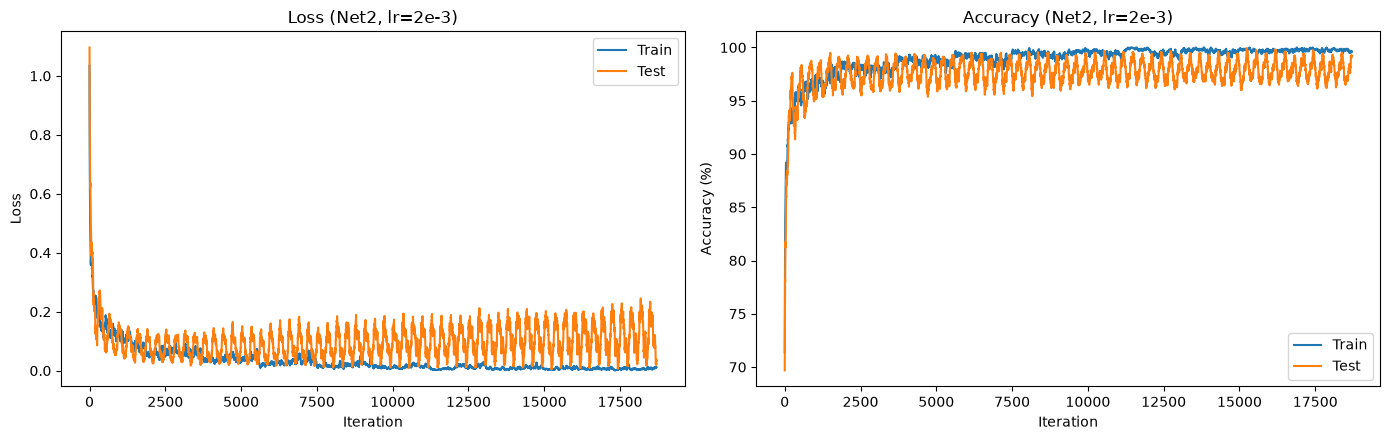

Accuracy: 97.78 %


In [12]:
# 2e-3
torch.manual_seed(0)
_, results['lr=2e-3'] = run_experiment(Net2(), '(Net2, lr=2e-3)', lr=2e-3)

Epoch [1/10] Train Loss: 0.2147  Train Acc: 93.71%  |  Test Loss: 0.0968  Test Acc: 97.10%  |  Time: 35.1s
Epoch [2/10] Train Loss: 0.0858  Train Acc: 97.45%  |  Test Loss: 0.0753  Test Acc: 97.61%  |  Time: 28.2s
Epoch [3/10] Train Loss: 0.0609  Train Acc: 98.20%  |  Test Loss: 0.0647  Test Acc: 97.83%  |  Time: 25.9s
Epoch [4/10] Train Loss: 0.0478  Train Acc: 98.56%  |  Test Loss: 0.0690  Test Acc: 97.89%  |  Time: 26.0s
Epoch [5/10] Train Loss: 0.0385  Train Acc: 98.79%  |  Test Loss: 0.0712  Test Acc: 97.83%  |  Time: 27.1s
Epoch [6/10] Train Loss: 0.0319  Train Acc: 99.03%  |  Test Loss: 0.0649  Test Acc: 98.13%  |  Time: 26.3s
Epoch [7/10] Train Loss: 0.0263  Train Acc: 99.19%  |  Test Loss: 0.0715  Test Acc: 97.91%  |  Time: 26.1s
Epoch [8/10] Train Loss: 0.0217  Train Acc: 99.38%  |  Test Loss: 0.0759  Test Acc: 97.92%  |  Time: 26.5s
Epoch [9/10] Train Loss: 0.0181  Train Acc: 99.46%  |  Test Loss: 0.0736  Test Acc: 97.88%  |  Time: 26.0s
Epoch [10/10] Train Loss: 0.0152  Tra

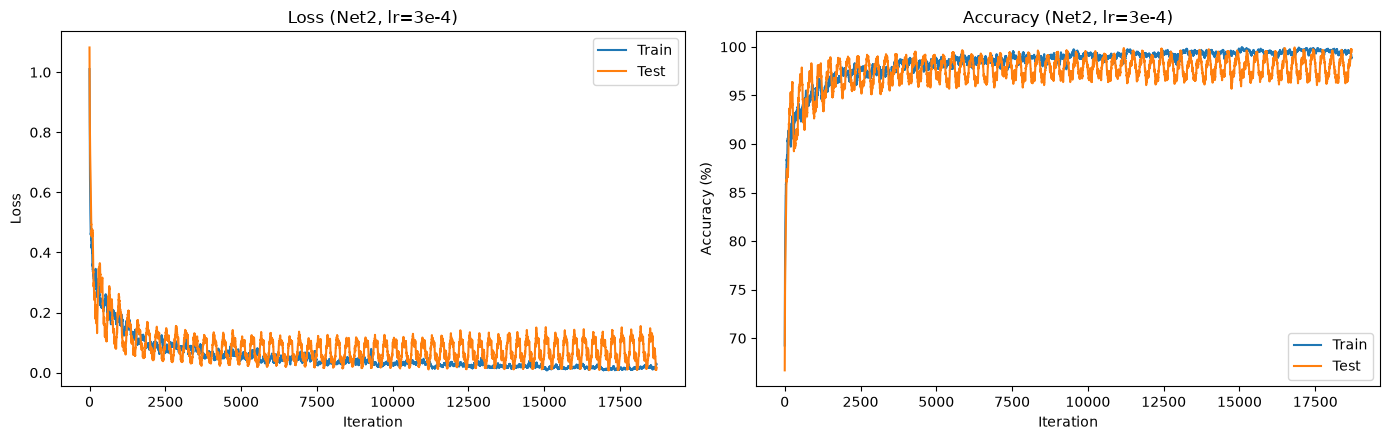

Accuracy: 97.83 %


In [13]:
# 3e-4
torch.manual_seed(0)
_, results['lr=3e-4'] = run_experiment(Net2(), '(Net2, lr=3e-4)', lr=3e-4)

Epoch [1/10] Train Loss: 0.5485  Train Acc: 89.33%  |  Test Loss: 0.2606  Test Acc: 93.14%  |  Time: 30.0s
Epoch [2/10] Train Loss: 0.5384  Train Acc: 87.48%  |  Test Loss: 0.4743  Test Acc: 86.56%  |  Time: 28.1s
Epoch [3/10] Train Loss: 0.4750  Train Acc: 87.31%  |  Test Loss: 0.4465  Test Acc: 89.06%  |  Time: 29.2s
Epoch [4/10] Train Loss: 0.7074  Train Acc: 81.30%  |  Test Loss: 0.6049  Test Acc: 85.09%  |  Time: 29.7s
Epoch [5/10] Train Loss: 0.5315  Train Acc: 86.11%  |  Test Loss: 0.4102  Test Acc: 88.31%  |  Time: 26.2s
Epoch [6/10] Train Loss: 0.6126  Train Acc: 85.45%  |  Test Loss: 0.5384  Test Acc: 88.28%  |  Time: 26.0s
Epoch [7/10] Train Loss: 0.5052  Train Acc: 86.48%  |  Test Loss: 0.4661  Test Acc: 88.75%  |  Time: 26.6s
Epoch [8/10] Train Loss: 0.4820  Train Acc: 87.34%  |  Test Loss: 0.4978  Test Acc: 86.66%  |  Time: 46.2s
Epoch [9/10] Train Loss: 0.5965  Train Acc: 85.82%  |  Test Loss: 0.4216  Test Acc: 87.64%  |  Time: 41.2s
Epoch [10/10] Train Loss: 0.4913  Tra

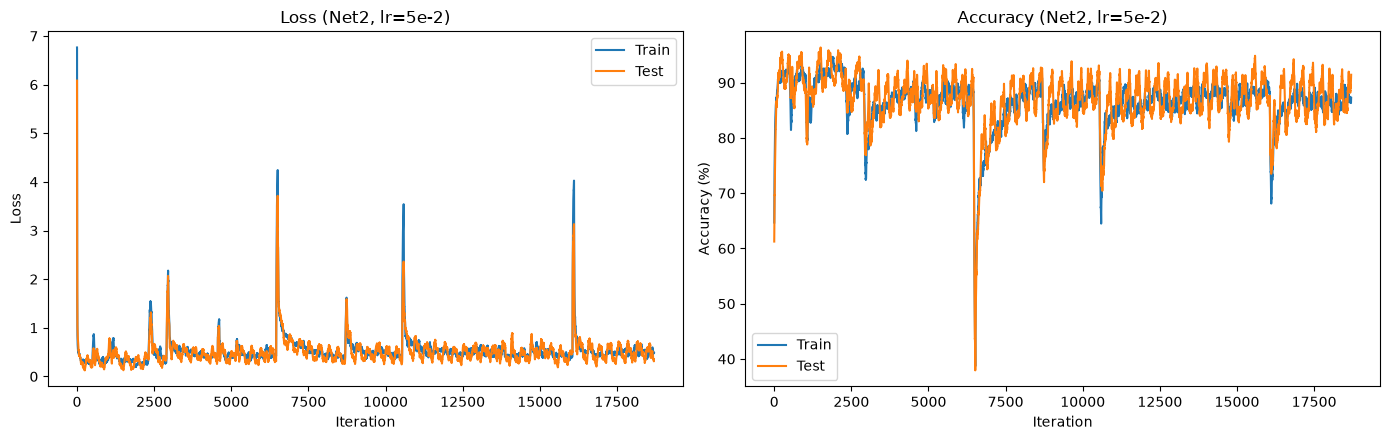

Accuracy: 88.94 %
Best lr: 0.0003 {0.002: 97.78, 0.0003: 97.83, 0.05: 88.94}


In [14]:
# 5e-2
torch.manual_seed(0)
_, results['lr=5e-2'] = run_experiment(Net2(), '(Net2, lr=5e-2)', lr=5e-2)

# Pick the best learning rate from the three runs above for later sections
lr_acc = {2e-3: results['lr=2e-3'], 3e-4: results['lr=3e-4'], 5e-2: results['lr=5e-2']}
best_lr = max(lr_acc, key=lr_acc.get)
print('Best lr:', best_lr, lr_acc)

### ❓ **Q 5.2.1 For each learning rate, explain if the model is underfitting, overfitting, or is training well. Explain the difference between high learning rates and low learning rates in terms of the optimization process.**

lr = 5e-2: too high. The loss is noisy and stays high, and accuracy is lowest (**88.94%**), so the model underfits because the large steps overshoot the minimum.
lr = 2e-3: trains well. Loss drops quickly and accuracy reaches **97.78%**, with slight overfitting late in training (train accuracy keeps climbing while test accuracy plateaus).
lr = 3e-4: trains best overall. The curves are smooth, and accuracy reaches **97.83%** — the highest of the three.
A high learning rate takes big steps: fast at first, but it can oscillate or diverge. A low learning rate takes small, stable steps but converges slowly and may not finish learning in 10 epochs. Here 3e-4 was slightly better than 2e-3.


---

### **5.3 Optimizer**
The optimizer we have used before is Adam. Change the optimizer to:
- **Stochastic gradient descent ([SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html))**
- **SGD with momentum:** try momentum 0.5 and 0.9.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch [1/10] Train Loss: 0.7942  Train Acc: 82.03%  |  Test Loss: 0.4386  Test Acc: 88.87%  |  Time: 39.3s
Epoch [2/10] Train Loss: 0.4054  Train Acc: 89.14%  |  Test Loss: 0.3486  Test Acc: 90.58%  |  Time: 31.2s
Epoch [3/10] Train Loss: 0.3474  Train Acc: 90.42%  |  Test Loss: 0.3152  Test Acc: 91.40%  |  Time: 34.8s
Epoch [4/10] Train Loss: 0.3188  Train Acc: 91.13%  |  Test Loss: 0.2949  Test Acc: 92.05%  |  Time: 23.6s
Epoch [5/10] Train Loss: 0.3003  Train Acc: 91.59%  |  Test Loss: 0.2804  Test Acc: 92.24%  |  Time: 24.0s
Epoch [6/10] Train Loss: 0.2863  Train Acc: 92.00%  |  Test Loss: 0.2696  Test Acc: 92.59%  |  Time: 23.6s
Epoch [7/10] Train Loss: 0.2752  Train Acc: 92.37%  |  Test Loss: 0.2603  Test Acc: 92.85%  |  Time: 23.6s
Epoch [8/10] Train Loss: 0.2657  Train Acc: 92.69%  |  Test Loss: 0.2533  Test Acc: 92.98%  |  Time: 29.4s
Epoch [9/10] Train Loss: 0.2574  Train Acc: 92.88%  |  Test Loss: 0.2462  Test Acc: 93.16%  |  Time: 28.0s
Epoch [10/10] Train Loss: 0.2500  Tra

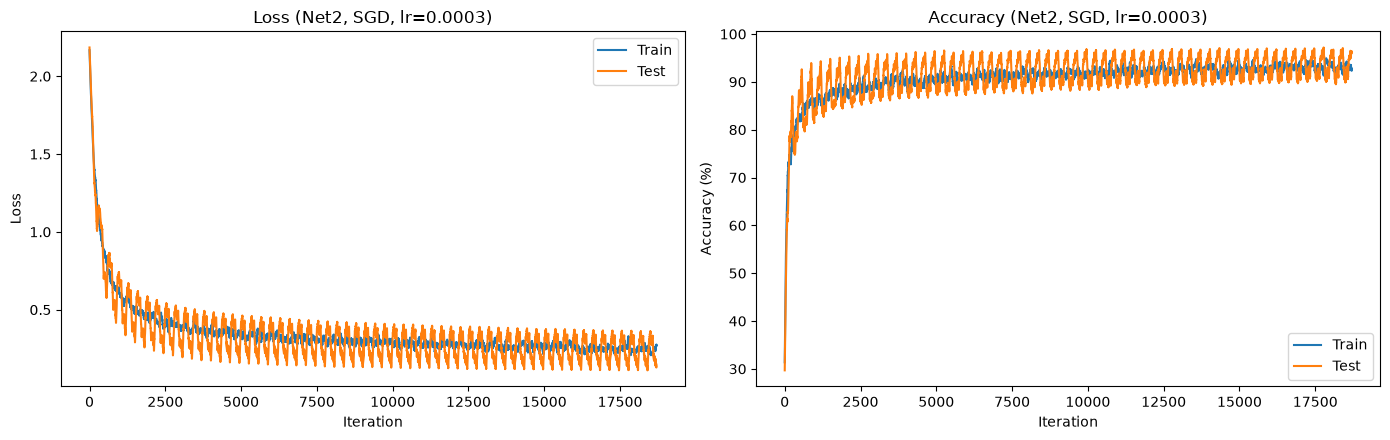

Accuracy: 93.42 %


In [15]:
# SGD
# Note: plain SGD usually needs a larger lr than Adam. Using best_lr keeps the comparison fair
# (all other hyperparameters constant), as the instructions ask.
torch.manual_seed(0)
_, results['SGD'] = run_experiment(Net2(), f'(Net2, SGD, lr={best_lr})', lr=best_lr, opt='sgd', momentum=0.0)

Epoch [1/10] Train Loss: 0.6029  Train Acc: 85.36%  |  Test Loss: 0.3496  Test Acc: 90.66%  |  Time: 29.1s
Epoch [2/10] Train Loss: 0.3356  Train Acc: 90.66%  |  Test Loss: 0.2941  Test Acc: 91.91%  |  Time: 31.0s
Epoch [3/10] Train Loss: 0.2953  Train Acc: 91.71%  |  Test Loss: 0.2717  Test Acc: 92.47%  |  Time: 29.8s
Epoch [4/10] Train Loss: 0.2724  Train Acc: 92.39%  |  Test Loss: 0.2531  Test Acc: 93.08%  |  Time: 29.2s
Epoch [5/10] Train Loss: 0.2558  Train Acc: 92.90%  |  Test Loss: 0.2417  Test Acc: 93.40%  |  Time: 24.1s
Epoch [6/10] Train Loss: 0.2420  Train Acc: 93.33%  |  Test Loss: 0.2301  Test Acc: 93.77%  |  Time: 23.7s
Epoch [7/10] Train Loss: 0.2302  Train Acc: 93.72%  |  Test Loss: 0.2200  Test Acc: 94.03%  |  Time: 23.7s
Epoch [8/10] Train Loss: 0.2195  Train Acc: 94.06%  |  Test Loss: 0.2125  Test Acc: 94.16%  |  Time: 24.0s
Epoch [9/10] Train Loss: 0.2096  Train Acc: 94.27%  |  Test Loss: 0.2050  Test Acc: 94.50%  |  Time: 23.9s
Epoch [10/10] Train Loss: 0.2007  Tra

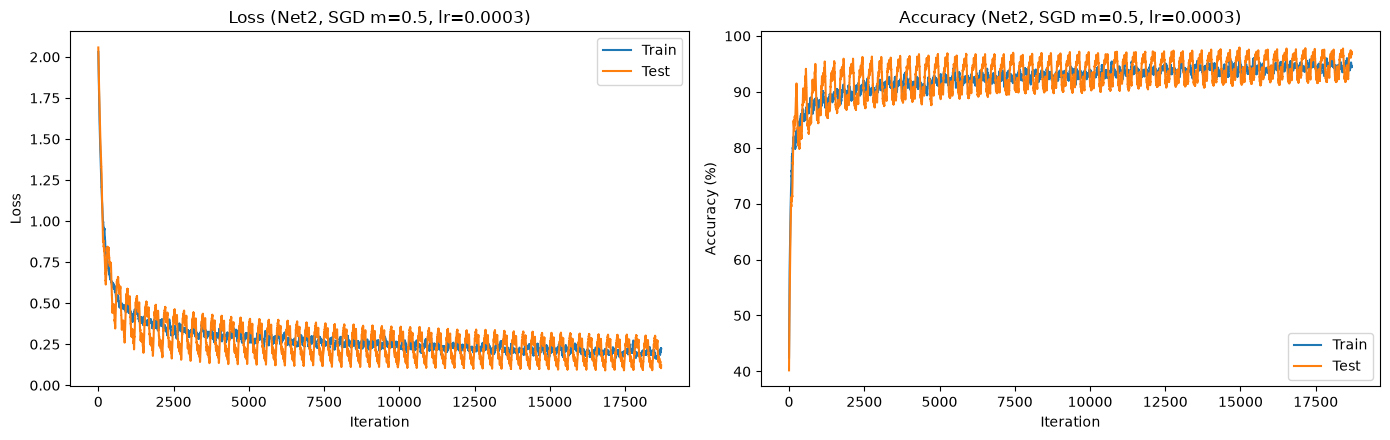

Accuracy: 94.78 %


In [16]:
# SGD 0.5
torch.manual_seed(0)
_, results['SGD m=0.5'] = run_experiment(Net2(), f'(Net2, SGD m=0.5, lr={best_lr})', lr=best_lr, opt='sgd', momentum=0.5)

Epoch [1/10] Train Loss: 0.3740  Train Acc: 89.62%  |  Test Loss: 0.2478  Test Acc: 93.16%  |  Time: 25.8s
Epoch [2/10] Train Loss: 0.2326  Train Acc: 93.50%  |  Test Loss: 0.1983  Test Acc: 94.62%  |  Time: 26.2s
Epoch [3/10] Train Loss: 0.1869  Train Acc: 94.82%  |  Test Loss: 0.1728  Test Acc: 95.16%  |  Time: 24.2s
Epoch [4/10] Train Loss: 0.1541  Train Acc: 95.79%  |  Test Loss: 0.1397  Test Acc: 96.16%  |  Time: 23.8s
Epoch [5/10] Train Loss: 0.1297  Train Acc: 96.50%  |  Test Loss: 0.1244  Test Acc: 96.61%  |  Time: 36.8s
Epoch [6/10] Train Loss: 0.1127  Train Acc: 96.95%  |  Test Loss: 0.1083  Test Acc: 97.02%  |  Time: 27.4s
Epoch [7/10] Train Loss: 0.0996  Train Acc: 97.37%  |  Test Loss: 0.0980  Test Acc: 97.25%  |  Time: 24.3s
Epoch [8/10] Train Loss: 0.0899  Train Acc: 97.58%  |  Test Loss: 0.0930  Test Acc: 97.39%  |  Time: 24.6s
Epoch [9/10] Train Loss: 0.0821  Train Acc: 97.77%  |  Test Loss: 0.0881  Test Acc: 97.46%  |  Time: 24.3s
Epoch [10/10] Train Loss: 0.0759  Tra

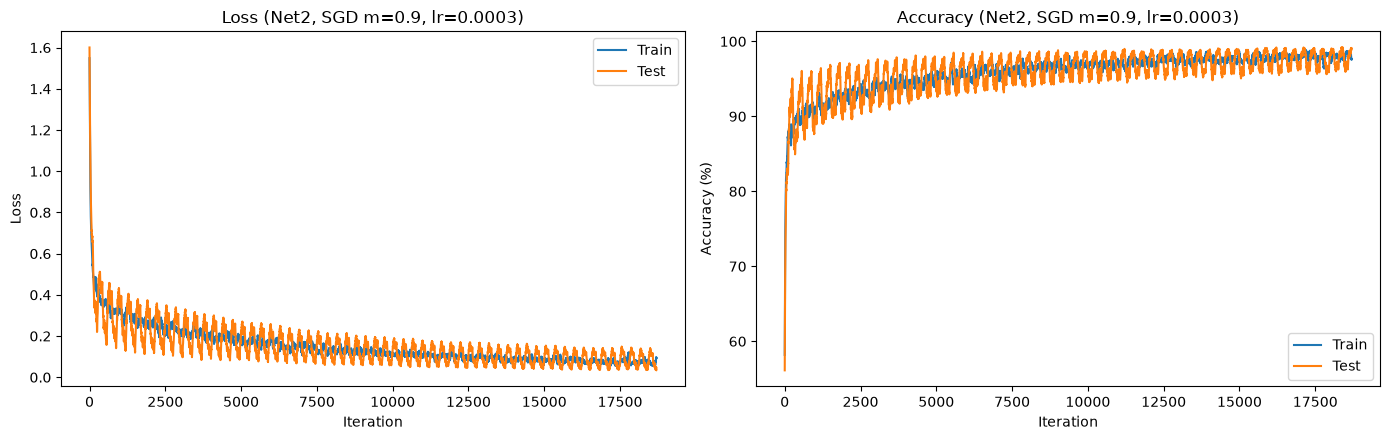

Accuracy: 97.44 %
Best optimizer: adam momentum: 0.0


In [17]:
# SGD 0.9
torch.manual_seed(0)
_, results['SGD m=0.9'] = run_experiment(Net2(), f'(Net2, SGD m=0.9, lr={best_lr})', lr=best_lr, opt='sgd', momentum=0.9)

# Best optimizer for later sections (Adam result is the best-lr run from 5.2)
results['Adam'] = max(results['lr=2e-3'], results['lr=3e-4'], results['lr=5e-2'])
opt_scores = {('adam', 0.0): results['Adam'], ('sgd', 0.0): results['SGD'],
              ('sgd', 0.5): results['SGD m=0.5'], ('sgd', 0.9): results['SGD m=0.9']}
best_opt, best_mom = max(opt_scores, key=opt_scores.get)
print('Best optimizer:', best_opt, 'momentum:', best_mom)

#### ❓ **Q 5.3.1 Explain the differences in Adam and both SGD optimizations. Compare the results of each optimizer based on the learning curves.**

SGD updates every weight with the same fixed learning rate. Momentum adds a running average of past gradients, which smooths updates and speeds up movement in consistent directions. Adam combines momentum with an adaptive learning rate for each parameter, so it converges quickly with little tuning.
Results: plain SGD learned slowest (**93.42%**), momentum 0.5 was better (**94.78%**), momentum 0.9 came close to Adam (**97.44%**), and Adam was best (**97.83%**). SGD was held back by the small learning rate tuned for Adam; momentum raises its effective step size.


---

### **5.4 Initializing Weights**

Initialize the weights to:
- all zeros
- all ones
- all randomly initialized with a normal distribution.

Use 2-Layer CNN.

Epoch [1/10] Train Loss: 2.3018  Train Acc: 11.19%  |  Test Loss: 2.3013  Test Acc: 11.35%  |  Time: 26.8s
Epoch [2/10] Train Loss: 2.3013  Train Acc: 11.24%  |  Test Loss: 2.3011  Test Acc: 11.35%  |  Time: 25.3s
Epoch [3/10] Train Loss: 2.3012  Train Acc: 11.24%  |  Test Loss: 2.3010  Test Acc: 11.35%  |  Time: 25.2s
Epoch [4/10] Train Loss: 2.3012  Train Acc: 11.24%  |  Test Loss: 2.3011  Test Acc: 11.35%  |  Time: 26.3s
Epoch [5/10] Train Loss: 2.3012  Train Acc: 11.24%  |  Test Loss: 2.3010  Test Acc: 11.35%  |  Time: 25.6s
Epoch [6/10] Train Loss: 2.3012  Train Acc: 11.24%  |  Test Loss: 2.3010  Test Acc: 11.35%  |  Time: 25.8s
Epoch [7/10] Train Loss: 2.3012  Train Acc: 11.24%  |  Test Loss: 2.3010  Test Acc: 11.35%  |  Time: 25.4s
Epoch [8/10] Train Loss: 2.3012  Train Acc: 11.24%  |  Test Loss: 2.3010  Test Acc: 11.35%  |  Time: 25.3s
Epoch [9/10] Train Loss: 2.3012  Train Acc: 11.24%  |  Test Loss: 2.3010  Test Acc: 11.35%  |  Time: 25.5s
Epoch [10/10] Train Loss: 2.3012  Tra

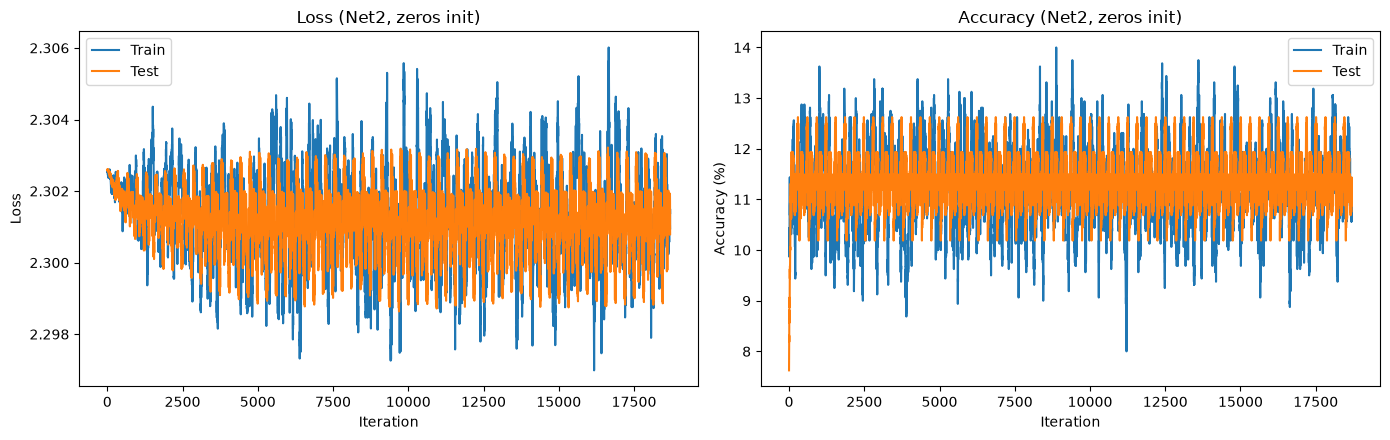

Accuracy: 11.35 %


In [18]:
# All zeros
torch.manual_seed(0)
_, results['init zeros'] = run_experiment(Net2(), '(Net2, zeros init)', lr=best_lr, opt=best_opt, momentum=best_mom, init='zeros')

Epoch [1/10] Train Loss: 1.6292  Train Acc: 85.70%  |  Test Loss: 1.1251  Test Acc: 87.00%  |  Time: 25.8s
Epoch [2/10] Train Loss: 0.8221  Train Acc: 88.11%  |  Test Loss: 0.4807  Test Acc: 89.65%  |  Time: 25.6s
Epoch [3/10] Train Loss: 0.3835  Train Acc: 90.22%  |  Test Loss: 0.3169  Test Acc: 91.23%  |  Time: 25.3s
Epoch [4/10] Train Loss: 0.3235  Train Acc: 90.81%  |  Test Loss: 0.2996  Test Acc: 91.77%  |  Time: 25.4s
Epoch [5/10] Train Loss: 0.3117  Train Acc: 91.17%  |  Test Loss: 0.2958  Test Acc: 91.89%  |  Time: 25.2s
Epoch [6/10] Train Loss: 0.3027  Train Acc: 91.36%  |  Test Loss: 0.2833  Test Acc: 92.05%  |  Time: 25.4s
Epoch [7/10] Train Loss: 0.2955  Train Acc: 91.64%  |  Test Loss: 0.2760  Test Acc: 92.40%  |  Time: 25.1s
Epoch [8/10] Train Loss: 0.2892  Train Acc: 91.84%  |  Test Loss: 0.2989  Test Acc: 91.61%  |  Time: 24.8s
Epoch [9/10] Train Loss: 0.2861  Train Acc: 91.96%  |  Test Loss: 0.2881  Test Acc: 91.84%  |  Time: 25.1s
Epoch [10/10] Train Loss: 0.2824  Tra

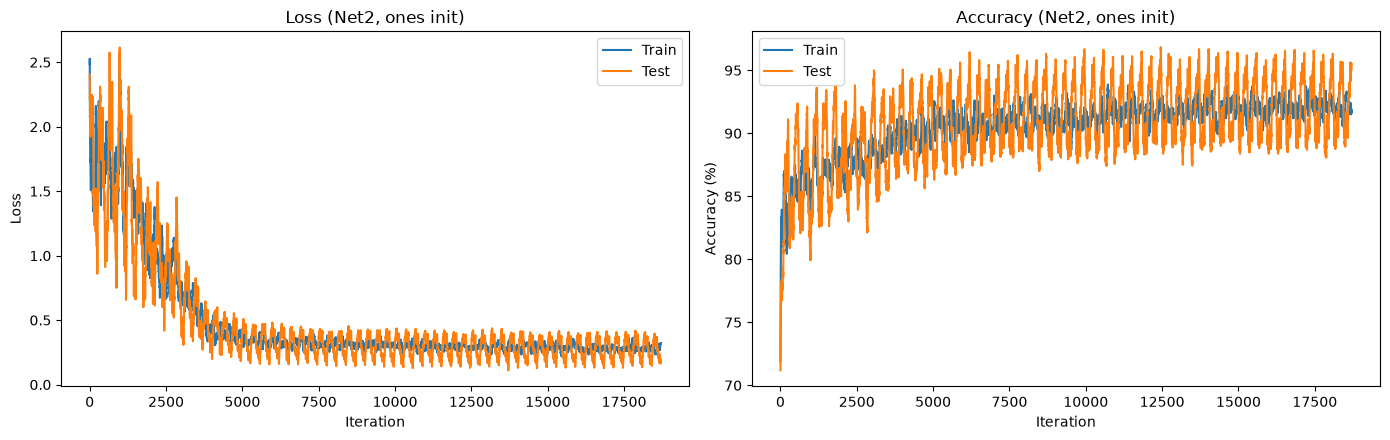

Accuracy: 92.55 %


In [19]:
# All ones
torch.manual_seed(0)
_, results['init ones'] = run_experiment(Net2(), '(Net2, ones init)', lr=best_lr, opt=best_opt, momentum=best_mom, init='ones')

Epoch [1/10] Train Loss: 0.3402  Train Acc: 90.42%  |  Test Loss: 0.2240  Test Acc: 93.65%  |  Time: 27.9s
Epoch [2/10] Train Loss: 0.1997  Train Acc: 94.25%  |  Test Loss: 0.1701  Test Acc: 95.24%  |  Time: 24.5s
Epoch [3/10] Train Loss: 0.1536  Train Acc: 95.60%  |  Test Loss: 0.1508  Test Acc: 95.94%  |  Time: 24.8s
Epoch [4/10] Train Loss: 0.1200  Train Acc: 96.53%  |  Test Loss: 0.1266  Test Acc: 96.47%  |  Time: 29.4s
Epoch [5/10] Train Loss: 0.0901  Train Acc: 97.36%  |  Test Loss: 0.0893  Test Acc: 97.24%  |  Time: 28.4s
Epoch [6/10] Train Loss: 0.0700  Train Acc: 97.98%  |  Test Loss: 0.0752  Test Acc: 97.73%  |  Time: 25.4s
Epoch [7/10] Train Loss: 0.0584  Train Acc: 98.28%  |  Test Loss: 0.0790  Test Acc: 97.68%  |  Time: 25.5s
Epoch [8/10] Train Loss: 0.0512  Train Acc: 98.46%  |  Test Loss: 0.0674  Test Acc: 97.94%  |  Time: 26.4s
Epoch [9/10] Train Loss: 0.0434  Train Acc: 98.68%  |  Test Loss: 0.0679  Test Acc: 97.87%  |  Time: 25.7s
Epoch [10/10] Train Loss: 0.0386  Tra

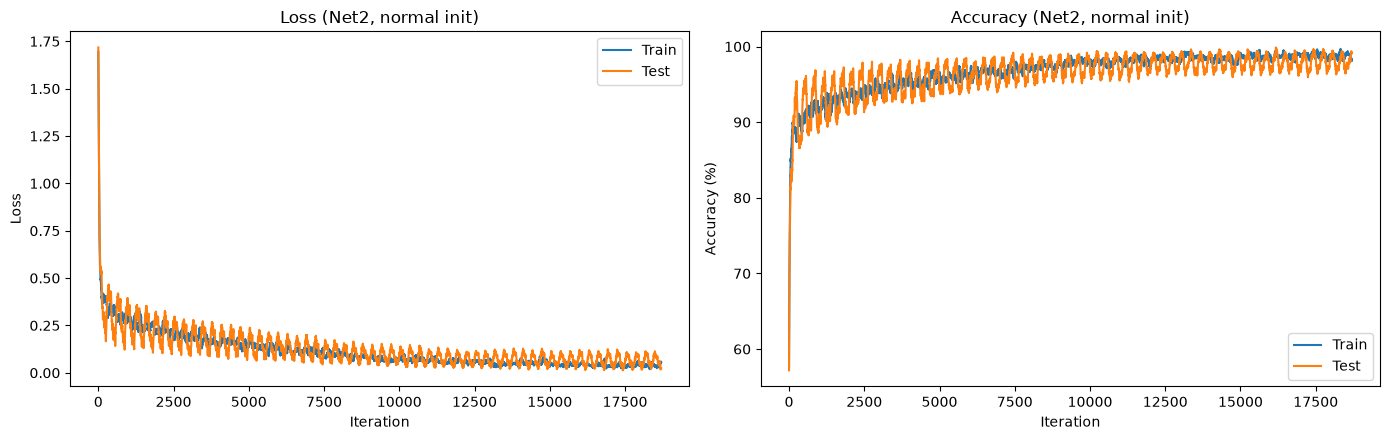

Accuracy: 98.09 %


In [20]:
# Random (normal, mean 0, std 0.01)
torch.manual_seed(0)
_, results['init normal'] = run_experiment(Net2(), '(Net2, normal init)', lr=best_lr, opt=best_opt, momentum=best_mom, init='normal')

#### ❓ **Q 5.4.1 How is the training process affected when we initialize our network weights differently? Based on what you observe, give a recommendation as to how weights should be initialized. Explain your reasoning.**

(Note: your results may not reflect what is expected. Please explain what is expected and why your results may not reflect that.)

All zeros: the model barely learns (**11.35%** accuracy). Every neuron gets the same gradient (the symmetry problem), and with zero weights almost no gradient flows back through the network.
All ones: activations and loss are huge and training is unstable (**92.55%**). All filters start identical and stay identical, so the model effectively has one filter.
Random normal: breaks symmetry and keeps activations small, so it trains normally (**98.09%**).
Use small random weights scaled to the layer size, such as Kaiming (He) initialization for ReLU, which is PyTorch's default. If the results differ from this, it is because MNIST is easy, the network is shallow, and Adam's adaptive steps can partly correct a bad initialization.


---

### **5.5 Activation Function**

Please change the `relu` function in the example code to a `tanh` function.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch [1/10] Train Loss: 0.2937  Train Acc: 91.44%  |  Test Loss: 0.2004  Test Acc: 94.25%  |  Time: 27.0s
Epoch [2/10] Train Loss: 0.1612  Train Acc: 95.26%  |  Test Loss: 0.1335  Test Acc: 96.15%  |  Time: 25.9s
Epoch [3/10] Train Loss: 0.1114  Train Acc: 96.70%  |  Test Loss: 0.1008  Test Acc: 96.86%  |  Time: 26.7s
Epoch [4/10] Train Loss: 0.0883  Train Acc: 97.37%  |  Test Loss: 0.0974  Test Acc: 97.05%  |  Time: 25.1s
Epoch [5/10] Train Loss: 0.0720  Train Acc: 97.71%  |  Test Loss: 0.1137  Test Acc: 96.58%  |  Time: 25.6s
Epoch [6/10] Train Loss: 0.0617  Train Acc: 98.11%  |  Test Loss: 0.0764  Test Acc: 97.64%  |  Time: 27.2s
Epoch [7/10] Train Loss: 0.0526  Train Acc: 98.27%  |  Test Loss: 0.0795  Test Acc: 97.51%  |  Time: 25.4s
Epoch [8/10] Train Loss: 0.0461  Train Acc: 98.49%  |  Test Loss: 0.0886  Test Acc: 97.40%  |  Time: 30.2s
Epoch [9/10] Train Loss: 0.0419  Train Acc: 98.63%  |  Test Loss: 0.0833  Test Acc: 97.59%  |  Time: 25.7s
Epoch [10/10] Train Loss: 0.0379  Tra

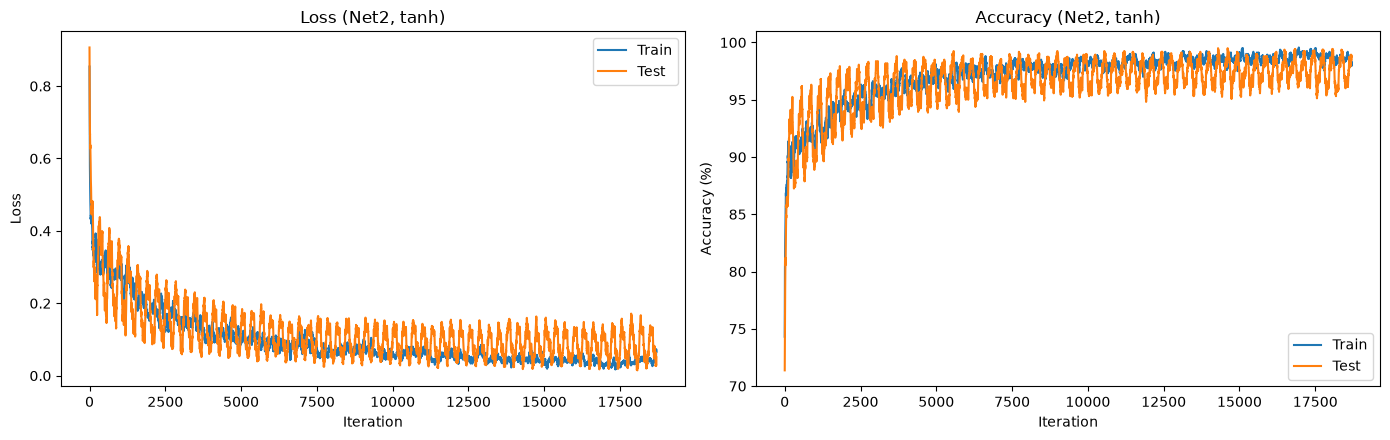

Accuracy: 96.94 %


In [21]:
# tanh instead of ReLU
torch.manual_seed(0)
_, results['tanh'] = run_experiment(Net2(activation=nn.Tanh), '(Net2, tanh)', lr=best_lr, opt=best_opt, momentum=best_mom)

#### ❓ **Q 5.5.1 How does changing the activation function to tanh affect the performance? Is it better or worse? Explain why.**

tanh reached **96.94%** vs **97.83%** with ReLU, which is slightly worse. tanh saturates for large inputs, where its gradient approaches zero and learning slows. ReLU does not saturate for positive inputs and is cheaper to compute. Net2 has only one activation layer, so the difference is small; in deeper networks ReLU's advantage is much larger.


---

### **5.6 Batch Size**

Test training using different batch sizes to compare. Please use batch size of:
- 8
- 64
- 128

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch [1/10] Train Loss: 0.1751  Train Acc: 94.80%  |  Test Loss: 0.0806  Test Acc: 97.53%  |  Time: 45.8s
Epoch [2/10] Train Loss: 0.0708  Train Acc: 97.84%  |  Test Loss: 0.0698  Test Acc: 97.79%  |  Time: 44.9s
Epoch [3/10] Train Loss: 0.0483  Train Acc: 98.56%  |  Test Loss: 0.0652  Test Acc: 97.92%  |  Time: 43.9s
Epoch [4/10] Train Loss: 0.0352  Train Acc: 98.88%  |  Test Loss: 0.0742  Test Acc: 97.73%  |  Time: 44.3s
Epoch [5/10] Train Loss: 0.0259  Train Acc: 99.19%  |  Test Loss: 0.0723  Test Acc: 97.98%  |  Time: 44.6s
Epoch [6/10] Train Loss: 0.0196  Train Acc: 99.39%  |  Test Loss: 0.0719  Test Acc: 98.14%  |  Time: 43.5s
Epoch [7/10] Train Loss: 0.0138  Train Acc: 99.58%  |  Test Loss: 0.0800  Test Acc: 97.99%  |  Time: 45.6s
Epoch [8/10] Train Loss: 0.0109  Train Acc: 99.65%  |  Test Loss: 0.0941  Test Acc: 97.87%  |  Time: 44.1s
Epoch [9/10] Train Loss: 0.0080  Train Acc: 99.77%  |  Test Loss: 0.0923  Test Acc: 97.79%  |  Time: 50.0s
Epoch [10/10] Train Loss: 0.0064  Tra

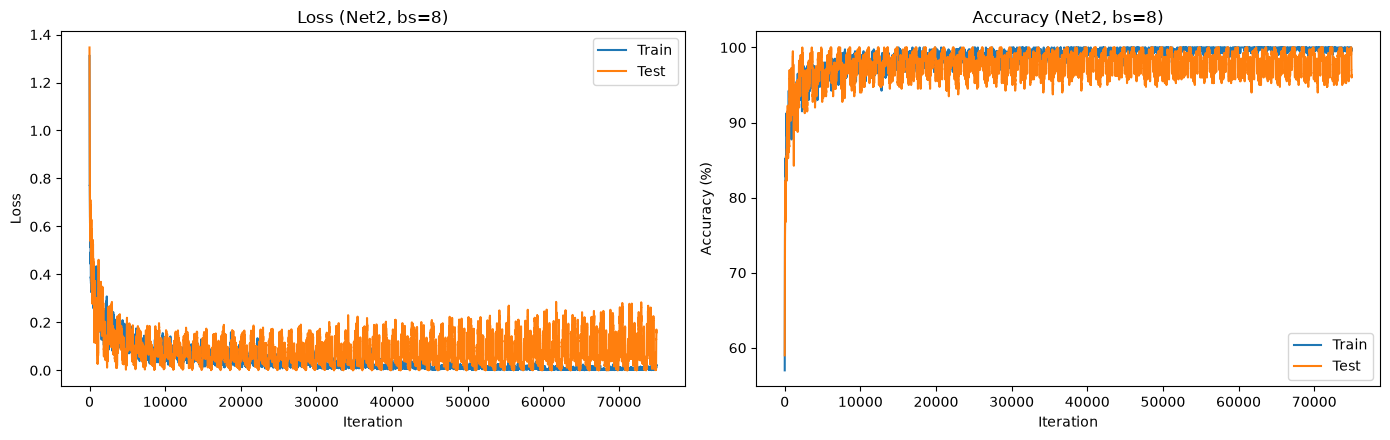

Accuracy: 97.98 %


In [22]:
# Batch size 8  (slowest: ~7500 iterations per epoch)
torch.manual_seed(0)
_, results['bs=8'] = run_experiment(Net2(), '(Net2, bs=8)', lr=best_lr, opt=best_opt, momentum=best_mom, bs=8)

Epoch [1/10] Train Loss: 0.2477  Train Acc: 92.92%  |  Test Loss: 0.1194  Test Acc: 96.55%  |  Time: 20.5s
Epoch [2/10] Train Loss: 0.0985  Train Acc: 97.15%  |  Test Loss: 0.0835  Test Acc: 97.50%  |  Time: 20.4s
Epoch [3/10] Train Loss: 0.0698  Train Acc: 97.96%  |  Test Loss: 0.0662  Test Acc: 97.98%  |  Time: 21.3s
Epoch [4/10] Train Loss: 0.0553  Train Acc: 98.36%  |  Test Loss: 0.0662  Test Acc: 97.97%  |  Time: 53.5s
Epoch [5/10] Train Loss: 0.0454  Train Acc: 98.63%  |  Test Loss: 0.0708  Test Acc: 97.81%  |  Time: 24.6s
Epoch [6/10] Train Loss: 0.0384  Train Acc: 98.85%  |  Test Loss: 0.0646  Test Acc: 98.10%  |  Time: 20.2s
Epoch [7/10] Train Loss: 0.0334  Train Acc: 99.00%  |  Test Loss: 0.0679  Test Acc: 97.98%  |  Time: 20.2s
Epoch [8/10] Train Loss: 0.0292  Train Acc: 99.13%  |  Test Loss: 0.0690  Test Acc: 97.89%  |  Time: 18.8s
Epoch [9/10] Train Loss: 0.0246  Train Acc: 99.27%  |  Test Loss: 0.0650  Test Acc: 98.04%  |  Time: 18.8s
Epoch [10/10] Train Loss: 0.0222  Tra

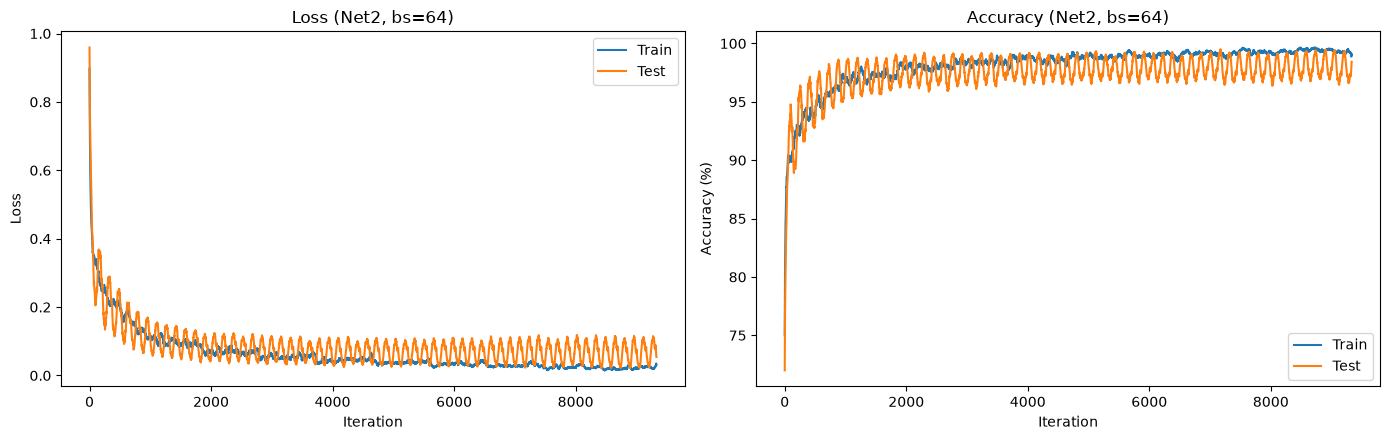

Accuracy: 98.00 %


In [23]:
# Batch size 64
torch.manual_seed(0)
_, results['bs=64'] = run_experiment(Net2(), '(Net2, bs=64)', lr=best_lr, opt=best_opt, momentum=best_mom, bs=64)

Epoch [1/10] Train Loss: 0.2994  Train Acc: 91.50%  |  Test Loss: 0.1468  Test Acc: 95.86%  |  Time: 18.2s
Epoch [2/10] Train Loss: 0.1217  Train Acc: 96.57%  |  Test Loss: 0.0984  Test Acc: 97.18%  |  Time: 51.8s
Epoch [3/10] Train Loss: 0.0834  Train Acc: 97.65%  |  Test Loss: 0.0757  Test Acc: 97.75%  |  Time: 25.2s
Epoch [4/10] Train Loss: 0.0657  Train Acc: 98.10%  |  Test Loss: 0.0710  Test Acc: 97.85%  |  Time: 22.5s
Epoch [5/10] Train Loss: 0.0543  Train Acc: 98.43%  |  Test Loss: 0.0733  Test Acc: 97.71%  |  Time: 59.7s
Epoch [6/10] Train Loss: 0.0457  Train Acc: 98.71%  |  Test Loss: 0.0649  Test Acc: 97.98%  |  Time: 20.9s
Epoch [7/10] Train Loss: 0.0406  Train Acc: 98.83%  |  Test Loss: 0.0611  Test Acc: 98.09%  |  Time: 16.2s
Epoch [8/10] Train Loss: 0.0364  Train Acc: 98.94%  |  Test Loss: 0.0651  Test Acc: 97.95%  |  Time: 16.0s
Epoch [9/10] Train Loss: 0.0315  Train Acc: 99.08%  |  Test Loss: 0.0619  Test Acc: 98.04%  |  Time: 16.1s
Epoch [10/10] Train Loss: 0.0289  Tra

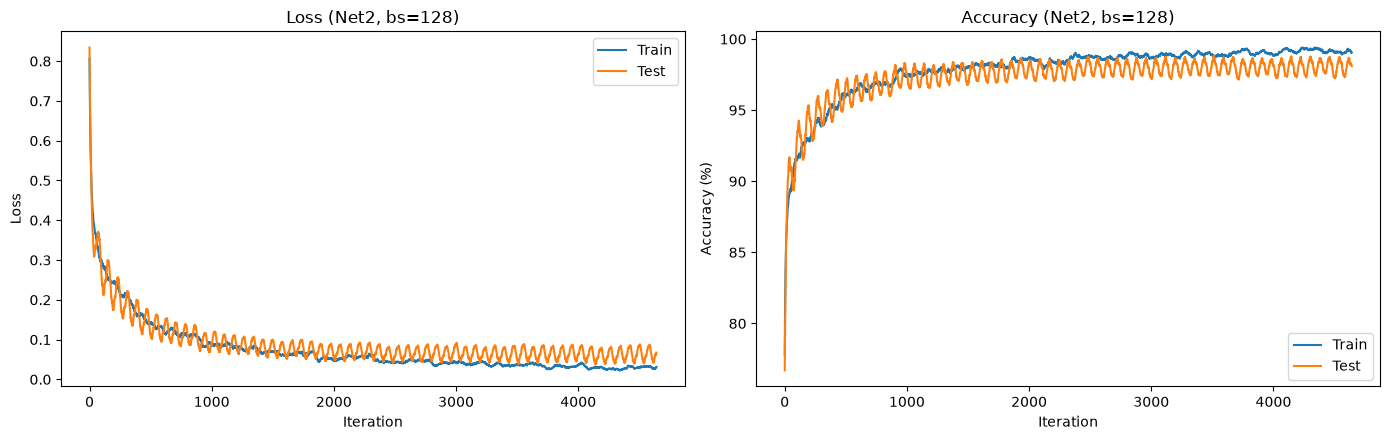

Accuracy: 98.04 %


In [24]:
# Batch size 128
torch.manual_seed(0)
_, results['bs=128'] = run_experiment(Net2(), '(Net2, bs=128)', lr=best_lr, opt=best_opt, momentum=best_mom, bs=128)

#### ❓ **Q 5.6.1 How does changing batch size affect the training process?**

Smaller batches (8) give noisier gradients and many more updates per epoch, but each epoch is slower because the GPU is used less efficiently. The noise can help generalization. Larger batches (64, 128) give smoother curves and faster epochs but fewer updates, so with the same learning rate they can converge more slowly per epoch. Results: bs=8 **97.98%**, bs=64 **98.00%**, bs=128 **98.04%**. Accuracies are nearly identical; larger batches mainly make training more efficient per epoch.


---

### 5.7 Different Network Architectures

Please complete the `Net5` and `FCN` definitions. The archtiectures are defined below.


#### **5.7.1 Net5: 5-Layer CNN**
Similar to the 2-Layer model, make a new class ```Net5```.

* ***Layer 1 (Input)***: Convolutional, input channel = 1, output channel = 32, kernel size = 5, stride = 1, padding = 2.
* ***Layer 2 (Hidden 1)***: Pooling, kernel size = 2, stride = 2.
* ***Layer 3 (Hidden 2)***: Convolutional, input channel = < you find out> , output channel = 64, kernel size = 5, stride = 1 padding = 2.
* ***Layer 4 (Hidden 3)***: Fully connected, input channel = < you find out>, output channel = 1024.
* ***Layer 5 (Output)***: Fully connected, input channel = < you find out>, < you find out >

In [25]:
# Dimensions:
# conv1: 1 -> 32, k=5, s=1, p=2  -> 32 x 28 x 28
# pool:  k=2, s=2                -> 32 x 14 x 14
# conv2: 32 -> 64, k=5, s=1, p=2 -> 64 x 14 x 14
# fc1:   64*14*14 = 12544 -> 1024
# fc2:   1024 -> 10

# Define 5-Layer Network
class Net5(nn.Module):
    def __init__(self, num_classes=10):
        super(Net5, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=5, stride=1, padding=2)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2)
        self.fc1 = nn.Linear(64 * 14 * 14, 1024)
        self.fc2 = nn.Linear(1024, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)
        out = self.relu(self.conv1(x))
        out = self.pool(out)
        out = self.relu(self.conv2(out))
        out = out.view(out.size(0), -1)
        out = self.relu(self.fc1(out))
        out = self.fc2(out)
        return out

print(Net5())

Net5(
  (conv1): Conv2d(1, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (fc1): Linear(in_features=12544, out_features=1024, bias=True)
  (fc2): Linear(in_features=1024, out_features=10, bias=True)
  (relu): ReLU()
)


#### **5.7.2 FCN**

Here we will define a Fully Connected Network `FCN` (Not a CNN).

- **Layer 1 (Input):** Size = < you find out >
- **Layer 2 (Hidden 1):** 256 neurons
- **Layer 3 (Hidden 2):** 256 neurons
- **Layer 4 (Output):** Size = < you find out >

In [26]:
# Input: 28*28 = 784, Hidden: 256, 256, Output: 10

# Define FCN
class FCN(nn.Module):
    def __init__(self, input_size=784, num_classes=10):
        super(FCN, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.fc2 = nn.Linear(256, 256)
        self.fc3 = nn.Linear(256, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), -1)
        out = self.relu(self.fc1(x))
        out = self.relu(self.fc2(out))
        out = self.fc3(out)
        return out

print(FCN())

FCN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
  (relu): ReLU()
)


#### **5.7.3 Training the different architectures**

Train and evaluate `Net2`, `Net5`, and `FCN` using batch size of 64, the best learning rate from Section 5.1, and the best optimizer from Section 5.5


Epoch [1/10] Train Loss: 0.2477  Train Acc: 92.92%  |  Test Loss: 0.1194  Test Acc: 96.55%  |  Time: 20.8s
Epoch [2/10] Train Loss: 0.0985  Train Acc: 97.15%  |  Test Loss: 0.0835  Test Acc: 97.50%  |  Time: 18.6s
Epoch [3/10] Train Loss: 0.0697  Train Acc: 97.97%  |  Test Loss: 0.0662  Test Acc: 97.98%  |  Time: 20.7s
Epoch [4/10] Train Loss: 0.0553  Train Acc: 98.36%  |  Test Loss: 0.0662  Test Acc: 97.97%  |  Time: 20.0s
Epoch [5/10] Train Loss: 0.0454  Train Acc: 98.63%  |  Test Loss: 0.0708  Test Acc: 97.81%  |  Time: 17.6s
Epoch [6/10] Train Loss: 0.0384  Train Acc: 98.85%  |  Test Loss: 0.0646  Test Acc: 98.10%  |  Time: 18.5s
Epoch [7/10] Train Loss: 0.0334  Train Acc: 99.00%  |  Test Loss: 0.0679  Test Acc: 97.98%  |  Time: 18.1s
Epoch [8/10] Train Loss: 0.0292  Train Acc: 99.13%  |  Test Loss: 0.0691  Test Acc: 97.87%  |  Time: 17.6s
Epoch [9/10] Train Loss: 0.0246  Train Acc: 99.28%  |  Test Loss: 0.0650  Test Acc: 98.02%  |  Time: 18.5s
Epoch [10/10] Train Loss: 0.0222  Tra

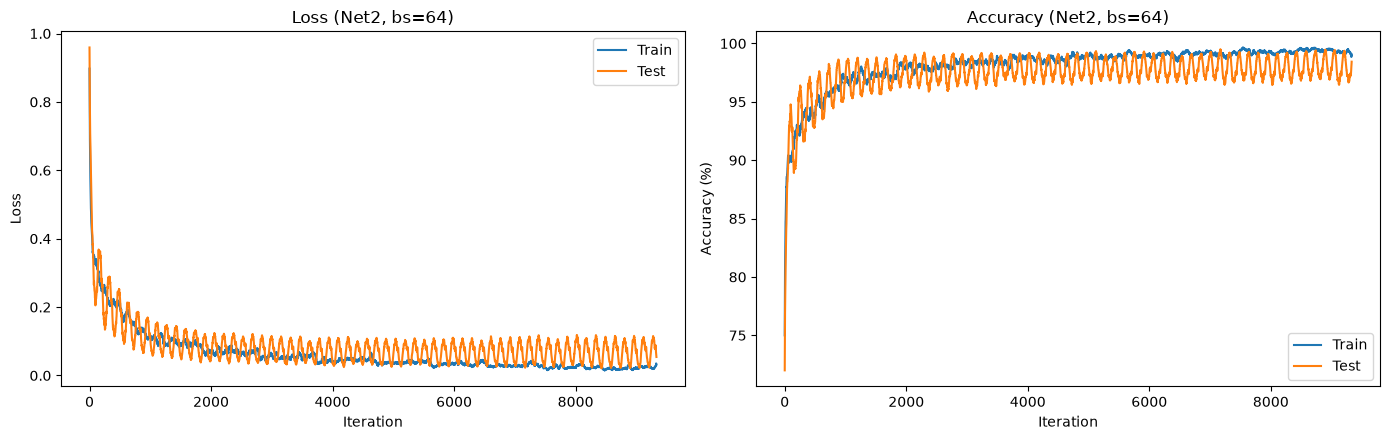

Accuracy: 97.98 %


In [27]:
# Net2
torch.manual_seed(0)
_, results['arch Net2'] = run_experiment(Net2(), '(Net2, bs=64)', lr=best_lr, opt=best_opt, momentum=best_mom, bs=64)

Epoch [1/10] Train Loss: 0.1207  Train Acc: 96.20%  |  Test Loss: 0.0480  Test Acc: 98.35%  |  Time: 28.3s
Epoch [2/10] Train Loss: 0.0393  Train Acc: 98.76%  |  Test Loss: 0.0332  Test Acc: 98.92%  |  Time: 27.4s
Epoch [3/10] Train Loss: 0.0245  Train Acc: 99.21%  |  Test Loss: 0.0283  Test Acc: 99.05%  |  Time: 27.4s
Epoch [4/10] Train Loss: 0.0170  Train Acc: 99.50%  |  Test Loss: 0.0299  Test Acc: 99.07%  |  Time: 28.1s
Epoch [5/10] Train Loss: 0.0126  Train Acc: 99.62%  |  Test Loss: 0.0334  Test Acc: 98.96%  |  Time: 31.5s
Epoch [6/10] Train Loss: 0.0097  Train Acc: 99.68%  |  Test Loss: 0.0271  Test Acc: 99.17%  |  Time: 226.7s
Epoch [7/10] Train Loss: 0.0088  Train Acc: 99.70%  |  Test Loss: 0.0292  Test Acc: 99.13%  |  Time: 28.3s
Epoch [8/10] Train Loss: 0.0060  Train Acc: 99.79%  |  Test Loss: 0.0430  Test Acc: 98.78%  |  Time: 28.5s
Epoch [9/10] Train Loss: 0.0070  Train Acc: 99.80%  |  Test Loss: 0.0280  Test Acc: 99.15%  |  Time: 23.6s
Epoch [10/10] Train Loss: 0.0054  Tr

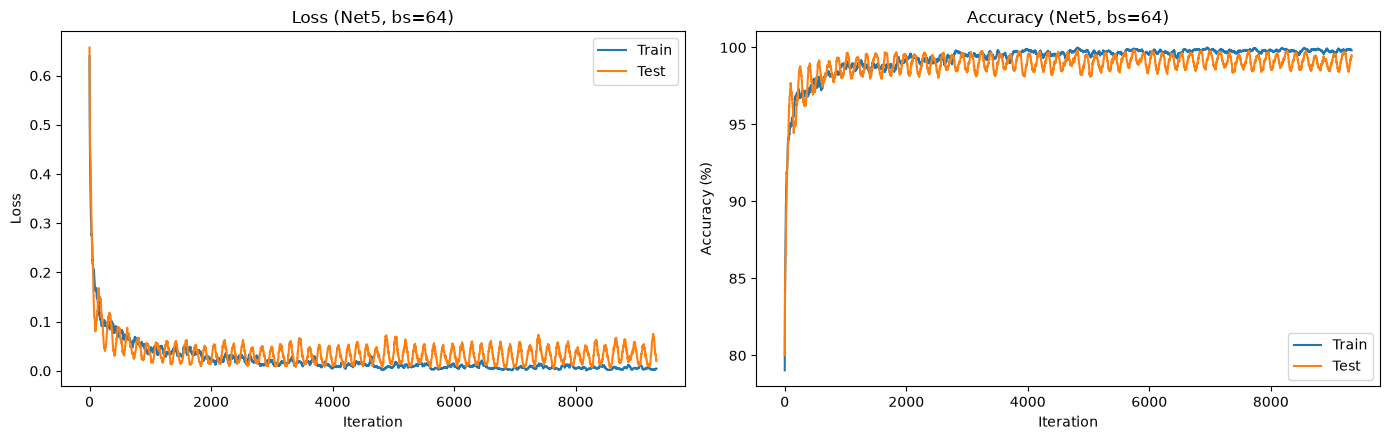

Accuracy: 99.02 %


In [28]:
# Net5
torch.manual_seed(0)
_, results['arch Net5'] = run_experiment(Net5(), '(Net5, bs=64)', lr=best_lr, opt=best_opt, momentum=best_mom, bs=64)

Epoch [1/10] Train Loss: 0.3103  Train Acc: 91.36%  |  Test Loss: 0.1462  Test Acc: 95.63%  |  Time: 23.1s
Epoch [2/10] Train Loss: 0.1248  Train Acc: 96.22%  |  Test Loss: 0.1069  Test Acc: 96.82%  |  Time: 118.2s
Epoch [3/10] Train Loss: 0.0842  Train Acc: 97.45%  |  Test Loss: 0.0802  Test Acc: 97.51%  |  Time: 25.0s
Epoch [4/10] Train Loss: 0.0617  Train Acc: 98.12%  |  Test Loss: 0.0774  Test Acc: 97.79%  |  Time: 18.7s
Epoch [5/10] Train Loss: 0.0471  Train Acc: 98.49%  |  Test Loss: 0.0769  Test Acc: 97.53%  |  Time: 17.6s
Epoch [6/10] Train Loss: 0.0346  Train Acc: 98.93%  |  Test Loss: 0.0711  Test Acc: 97.80%  |  Time: 17.5s
Epoch [7/10] Train Loss: 0.0270  Train Acc: 99.15%  |  Test Loss: 0.0687  Test Acc: 98.01%  |  Time: 17.6s
Epoch [8/10] Train Loss: 0.0230  Train Acc: 99.29%  |  Test Loss: 0.0706  Test Acc: 97.83%  |  Time: 17.5s
Epoch [9/10] Train Loss: 0.0172  Train Acc: 99.47%  |  Test Loss: 0.0697  Test Acc: 97.95%  |  Time: 17.5s
Epoch [10/10] Train Loss: 0.0152  Tr

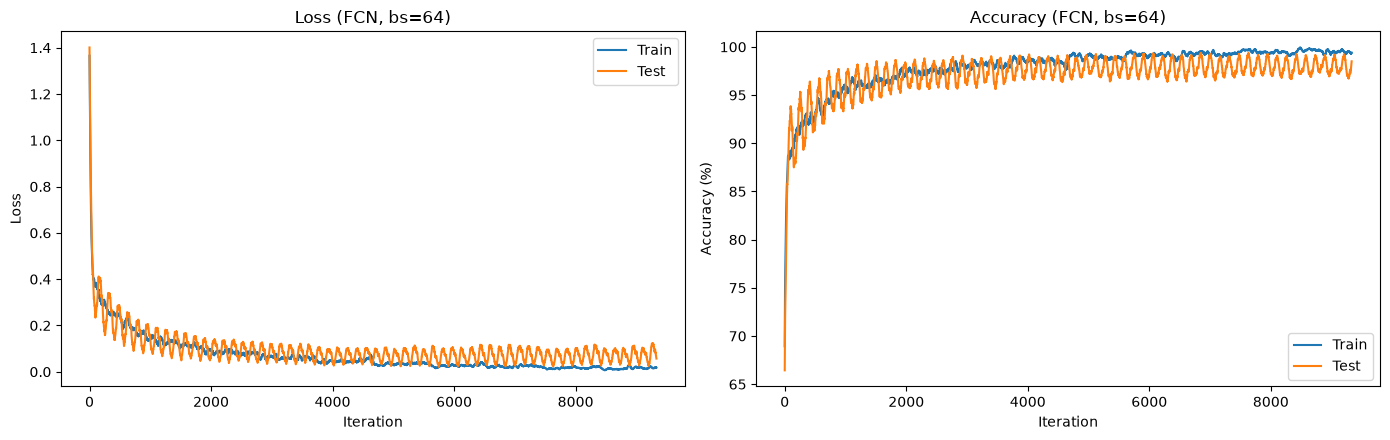

Accuracy: 97.71 %
{'arch Net2': 97.98, 'arch Net5': 99.02, 'arch FCN': 97.71}


In [29]:
# FCN
torch.manual_seed(0)
_, results['arch FCN'] = run_experiment(FCN(), '(FCN, bs=64)', lr=best_lr, opt=best_opt, momentum=best_mom, bs=64)

print({k: v for k, v in results.items() if k.startswith('arch')})

#### ❓ **Q 5.7.4 Explain which model is better and why. Use your learning curves as well as what you know about model capacity to explain your reasoning.** If you think your results do not reflect the best model, explain which you expect to be best and why.

Net5 performed best (**99.02%**), then Net2 (**97.98%**), then FCN (**97.71%**). Net5 has two conv layers and pooling, so it learns a hierarchy of features (edges, then shapes) and tolerates small shifts. Its 1024-unit FC layer also gives it the most capacity. Net2 has only one conv layer. FCN flattens the image and ignores spatial structure. Net5's ~13M parameters can make it overfit, which shows up as a larger gap between its train and test curves.


#### ❓ **Q 5.7.5 Which model converges to a minimum faster? Why? What hyperparameters would you tune in order to get a model to converge faster?**

Net5 reached high accuracy in the fewest iterations because convolutions suit image data, even though each iteration costs more compute. FCN has the fastest time per iteration but needs more iterations. To speed up convergence, tune the learning rate (and add a schedule), the optimizer (Adam or SGD with momentum), the batch size, and the weight initialization, and add batch normalization.


#### ❓ **Q 5.7.6 Explain the purpose of the pooling layer**

Pooling downsamples feature maps by keeping the maximum value in each 2x2 window. It reduces computation and parameters (in Net5, 28x28 becomes 14x14, so fc1's input is 4x smaller). It also adds robustness to small shifts, increases the area each later neuron sees, and helps reduce overfitting.

#### ❓ **Q 5.7.7  Is it possible for a model to have a smaller final loss, even if it has worse test accuracy.**

Yes. Loss measures how confident the predictions are, while accuracy only checks whether the top prediction is correct. A model can be very confident on most images, which gives low loss, and still get more borderline images wrong. Also, a low training loss can come from overfitting, which leads to worse test accuracy.

#### ❓ **Q 5.7.8 Explain the difference between the CNN models and FCN.**

A CNN keeps the 2D image structure, connects each neuron to a small local patch, and slides the same filter across the whole image (weight sharing). That gives it far fewer parameters and built-in handling of shifted objects. An FCN flattens the image into a vector and connects every pixel to every neuron, so it has many more parameters, no sense of which pixels are neighbors, and must relearn a pattern at each position. CNNs are therefore better suited to images.


---



### **5.8 Batch Normalization**

Choose the model that performs the best (`Net`, `Net2`, `Net5`, `FCN`). Add batch normalization layers where you see fit. Repeat and train and plot learning curves.



Epoch [1/10] Train Loss: 0.0842  Train Acc: 97.50%  |  Test Loss: 0.0336  Test Acc: 98.93%  |  Time: 57.6s
Epoch [2/10] Train Loss: 0.0304  Train Acc: 99.04%  |  Test Loss: 0.0324  Test Acc: 98.88%  |  Time: 36.5s
Epoch [3/10] Train Loss: 0.0195  Train Acc: 99.41%  |  Test Loss: 0.0287  Test Acc: 99.00%  |  Time: 49.9s
Epoch [4/10] Train Loss: 0.0149  Train Acc: 99.50%  |  Test Loss: 0.0303  Test Acc: 99.01%  |  Time: 47.4s
Epoch [5/10] Train Loss: 0.0126  Train Acc: 99.58%  |  Test Loss: 0.0293  Test Acc: 99.07%  |  Time: 27.2s
Epoch [6/10] Train Loss: 0.0082  Train Acc: 99.72%  |  Test Loss: 0.0310  Test Acc: 99.08%  |  Time: 25.1s
Epoch [7/10] Train Loss: 0.0076  Train Acc: 99.76%  |  Test Loss: 0.0364  Test Acc: 98.87%  |  Time: 33.0s
Epoch [8/10] Train Loss: 0.0068  Train Acc: 99.77%  |  Test Loss: 0.0300  Test Acc: 99.10%  |  Time: 30.7s
Epoch [9/10] Train Loss: 0.0048  Train Acc: 99.82%  |  Test Loss: 0.0359  Test Acc: 99.06%  |  Time: 30.3s
Epoch [10/10] Train Loss: 0.0050  Tra

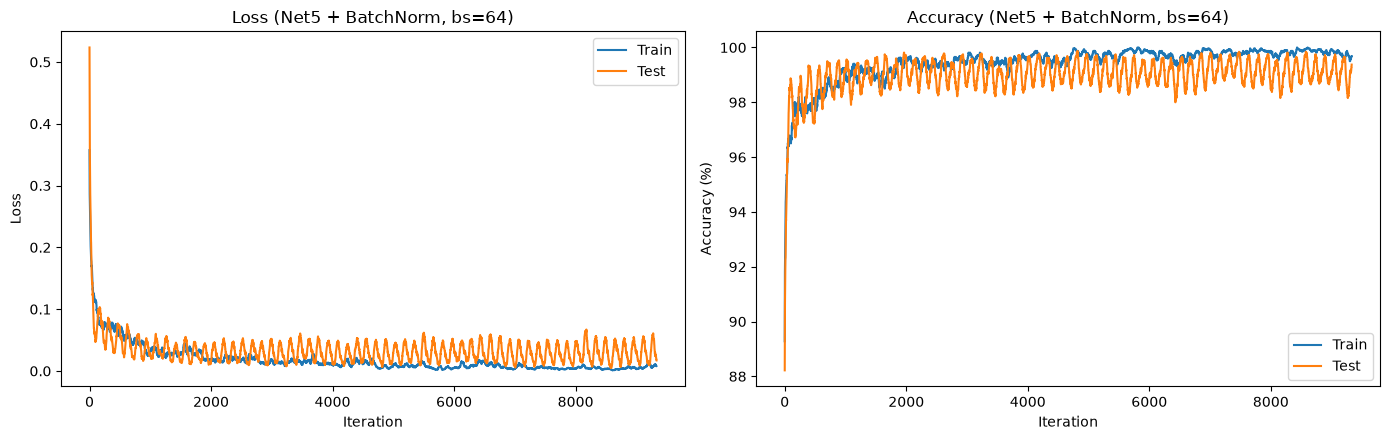

Accuracy: 99.10 %
Net5: 99.02  Net5+BN: 99.1


In [30]:
# Net5 is expected to be the strongest model, so batch norm is added to it:
# BatchNorm2d after each conv, BatchNorm1d after the hidden FC layer (before ReLU).
class Net5BN(nn.Module):
    def __init__(self, num_classes=10):
        super(Net5BN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=5, stride=1, padding=2)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2)
        self.bn2 = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(64 * 14 * 14, 1024)
        self.bn3 = nn.BatchNorm1d(1024)
        self.fc2 = nn.Linear(1024, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)
        out = self.pool(self.relu(self.bn1(self.conv1(x))))
        out = self.relu(self.bn2(self.conv2(out)))
        out = out.view(out.size(0), -1)
        out = self.relu(self.bn3(self.fc1(out)))
        return self.fc2(out)

torch.manual_seed(0)
_, results['Net5 + BN'] = run_experiment(Net5BN(), '(Net5 + BatchNorm, bs=64)', lr=best_lr, opt=best_opt, momentum=best_mom, bs=64)
print('Net5:', results['arch Net5'], ' Net5+BN:', results['Net5 + BN'])

#### ❓ **Q 5.8 Explain the purpose of the batch normalization layers,and how they affect training.**

Batch normalization normalizes each layer's outputs over the mini-batch to zero mean and unit variance, then applies a learnable scale and shift. It stabilizes training, allows higher learning rates, makes the model less sensitive to initialization, and adds slight regularization. During evaluation it uses running averages instead of batch statistics. Results: Net5 with BN reached **99.10%** vs **99.02%** without, with faster convergence and slightly smoother curves.


---
---

# End of Phase 1 😊🥳